### RBFOpt on the Small Batch Problem

This notebook demonstrates the application of **Radial Basis Function Optimization (RBFOpt)** to a **Small Batch** problem.
The notebook includes visualizations of the optimization trajectory and the best solution identified at each iteration.
When using **RBFOpt** for this problem, **BONMIN** is used as the **MINLP** solver and **IPOPT** is used as the **NLP** solver.

In [1]:
%%capture
import rbfopt
import numpy as np
import csv

In [2]:
minlp_solver_path=''
nlp_solver_path=''

In [4]:
def load_grid(filename="compl_enum_small_batch_baron.csv"):
    """
    Load grid data from CSV.
    Expected CSV columns: "x", "y", "Objective", among others.
    Returns a dictionary mapping (x, y) tuples to the objective value.
    """
    grid_data = {}
    with open(filename, "r") as f:
        reader = csv.DictReader(f)
        for row in reader:
            try:
                # Convert x and y values to integers
                x_val = int(row["x"])
                y_val = int(row["y"])
                z_val = int(row["z"])
                # Convert objective value to float
                obj_val = float(row["Objective"])
                grid_data[(x_val, y_val, z_val)] = obj_val
            except Exception as e:
                # Skip rows with conversion issues
                continue
    return grid_data
# Load the data from grid.csv
grid_data = load_grid()

# Determine grid bounds from the keys of grid_data
xs = [pt[0] for pt in grid_data.keys()]
ys = [pt[1] for pt in grid_data.keys()]
zs = [pt[2] for pt in grid_data.keys()]
min_x, max_x = min(xs), max(xs)
min_y, max_y = min(ys), max(ys)
min_z, max_z = min(zs), max(zs)
print("Grid bounds:")
print("x in [{}, {}]".format(min_x, max_x))
print("y in [{}, {}]".format(min_y, max_y))
print("z in [{}, {}]".format(min_z, max_z))

Grid bounds:
x in [2, 3]
y in [2, 3]
z in [1, 3]


In [5]:
# Load the data from grid.csv
grid_data = load_grid()

# PENALTY = 1e5  # adjust this penalty as appropriate
PENALTY = np.inf # use infinity as penalty for infeasible points
# PENALTY = np.nan  # use NaN as penalty for infeasible points
# PENALTY = None  # use None as penalty for infeasible points

def obj_funct(x):
    """
    Given a candidate point x (a list or 1-D numpy array with 2 elements),
    this function rounds x to the nearest integers and returns the objective value
    if the point exists in grid_data and is feasible (i.e. y <= x).
    Otherwise, returns a penalty value.
    """
    # Round the candidate coordinates to nearest integers
    x_int = int(round(x[0]))
    y_int = int(round(x[1]))
    z_int = int(round(x[2]))
    
    # # Check the feasibility of the point: for our lattice we require y <= x.
    # if y_int > x_int:
    #     return PENALTY

    # if objective is not a number, return penalty
    if not isinstance(x_int, (int, float)) or not isinstance(y_int, (int, float)) or not isinstance(z_int, (int, float)):
        return PENALTY
    
    # If the point exists in the grid, return its objective value.
    if (x_int, y_int, z_int) in grid_data:
        return grid_data[(x_int, y_int, z_int)]
    else:
        # If the point is not in the grid, return the penalty.
        return PENALTY

In [6]:
test_point = [2, 2, 1]
value = obj_funct(test_point)
print(f"For point {test_point} the objective value is {value}")

For point [2, 2, 1] the objective value is 167427.65711470306


In [7]:
# Set up the black-box for a 2D problem with integer variables.
# We use the determined bounds and mark both variables as integer ("I").
black_box = rbfopt.RbfoptUserBlackBox(
    3,  # number of dimensions
    np.array([2, 2, 1]),    # lower bounds for x and y
    np.array([3, 3, 3]),  # upper bounds for x and y
    np.array(["I", "I", "I"]),# both variables are integers
    obj_funct
)

# Configure optimization settings.
settings = rbfopt.RbfoptSettings(
    max_evaluations=10,  # maximum number of evaluations
    minlp_solver_path=minlp_solver_path, # path to the MINLP solver
    nlp_solver_path=nlp_solver_path, # path to the NLP solver
    algorithm='Gutmann',   # optimization algorithm variant # options = ['Gutmann', 'MSRSM']
    rbf='auto',           # allow automatic RBF selection
    global_search_method = 'sampling',  # options = ['sampling', 'genetic', 'solver']
)

# Create the optimization algorithm instance.
alg = rbfopt.RbfoptAlgorithm(settings, black_box)

# Run the optimization.
best_val, best_point, itercount, evalcount, fast_evalcount = alg.optimize()

print("Optimization completed.")
print("Best objective value found:", best_val)
print("At lattice point (rounded):", [int(round(v)) for v in best_point])
print("Iterations:", itercount, "Function evaluations:", evalcount)

  Iter  Cycle  Action             Objective value      Time      Gap
  ----  -----  ------             ---------------      ----      ---
     0      0  Initialization       178545.195839      0.01   100.00 *
     0      0  Initialization       260117.433533      0.01   100.00  
     0      0  Initialization       204601.967629      0.01   100.00  
     0      0  GlobalStep           185768.812505      0.01   100.00  
     1      0  GlobalStep           167427.657115      0.18   100.00 *
     2      0  GlobalStep           181201.665512      0.28   100.00  
     3      0  GlobalStep           209964.948666      0.42   100.00  
     4      0  GlobalStep           210580.838347      0.55   100.00  
     5      0  AdjLocalStep         222943.123019      0.65   100.00  
     6      1  Discarded                               0.66
     7      1  GlobalStep           241384.701493      0.77   100.00  
Summary: iters   8 evals  10 noisy_evals   0 cycles   1 opt_time    0.77 tot_time    0.77 ob

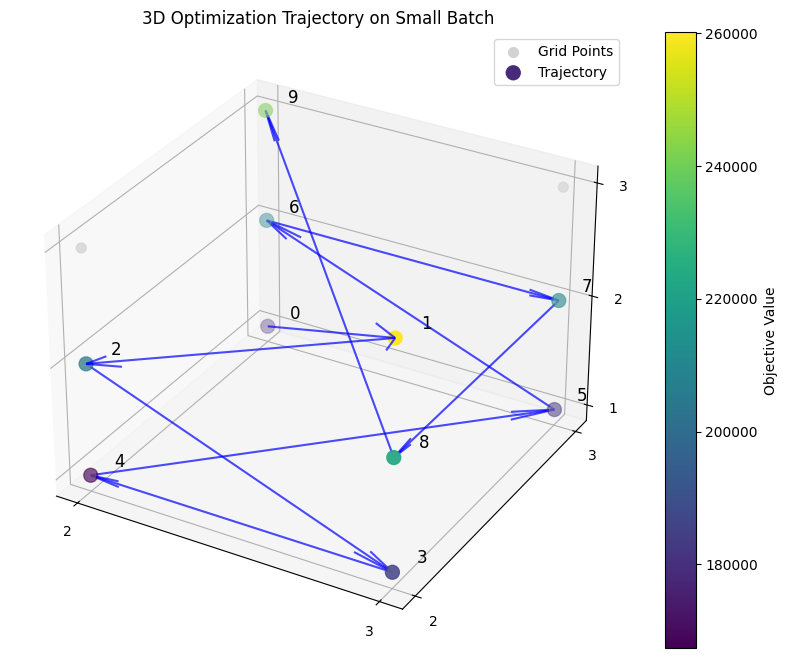

In [8]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # this import registers the 3D projection
import numpy as np

# Define grid bounds
x_bounds = [2, 3]
y_bounds = [2, 3]
z_bounds = [1, 3]

# Generate grid points (all integer combinations within the bounds)
grid_x, grid_y, grid_z = [], [], []
for x in range(x_bounds[0], x_bounds[1] + 1):
    for y in range(y_bounds[0], y_bounds[1] + 1):
        for z in range(z_bounds[0], z_bounds[1] + 1):
            grid_x.append(x)
            grid_y.append(y)
            grid_z.append(z)

# New iterations data
iterations = [
    (0, 178545.195839, [2.0, 3.0, 1.0]),
    (1, 260117.433533, [3.0, 2.0, 3.0]),
    (2, 204601.967629, [2.0, 2.0, 2.0]),
    (3, 185768.812505, [3.0, 2.0, 1.0]),
    (4, 167427.657115, [2.0, 2.0, 1.0]),
    (5, 181201.665512, [3.0, 3.0, 1.0]),
    (6, 209964.948666, [2.0, 3.0, 2.0]),
    (7, 210580.838347, [3.0, 3.0, 2.0]),
    (8, 222943.123019, [3.0, 2.0, 2.0]),
    (9, 241384.701493, [2.0, 3.0, 3.0])
]

# # New iterations data for solver
# iterations = [
#     (0, 178545.195839, [2.0, 3.0, 1.0]),
#     (1, 260117.433533, [3.0, 2.0, 3.0]),
#     (2, 204601.967629, [2.0, 2.0, 2.0]),
#     (3, 185768.812505, [3.0, 2.0, 1.0]),
#     (4, 167427.657115, [2.0, 2.0, 1.0]),
# ]

# Iter   0 Obj   178545.195839 Point [2. 3. 1.]
# Iter   1 Obj   260117.433533 Point [3. 2. 3.]
# Iter   2 Obj   204601.967629 Point [2. 2. 2.]
# Iter   3 Obj   185768.812505 Point [3. 2. 1.]
# Iter   4 Obj   167427.657115 Point [2. 2. 1.]

# Extract the coordinates and objective values from the iterations
trajectory_x = [pt[2][0] for pt in iterations]
trajectory_y = [pt[2][1] for pt in iterations]
trajectory_z = [pt[2][2] for pt in iterations]
trajectory_obj = [pt[1] for pt in iterations]

# Create a 3D figure
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the grid points in light gray
ax.scatter(grid_x, grid_y, grid_z, c='lightgray', label='Grid Points', s=50)

# Plot the trajectory points with a color mapping based on the objective value
sc = ax.scatter(trajectory_x, trajectory_y, trajectory_z, c=trajectory_obj, cmap='viridis', 
                label='Trajectory', s=100)
plt.colorbar(sc, label='Objective Value')

# Add arrows between trajectory points using 3D quiver
for i in range(len(trajectory_x) - 1):
    # Starting point of the arrow
    x0, y0, z0 = trajectory_x[i], trajectory_y[i], trajectory_z[i]
    # Calculate differences to the next point
    dx = trajectory_x[i+1] - x0
    dy = trajectory_y[i+1] - y0
    dz = trajectory_z[i+1] - z0
    # Draw an arrow with a small arrow head (using arrow_length_ratio)
    ax.quiver(x0, y0, z0, dx, dy, dz, arrow_length_ratio=0.1, color='blue', alpha=0.7)

# Add iteration numbers next to each trajectory point
for i, (x, y, z) in enumerate(zip(trajectory_x, trajectory_y, trajectory_z)):
    ax.text(x + 0.05, y + 0.05, z + 0.05, str(i), fontsize=12, color='black')

# Label axes and set title
# ax.set_xlabel(('Z_E, mixer', '$Z_{E,\\ mixer}$'))
# ax.set_ylabel(('Z_E, reactor', '$Z_{E,\\ reactor}$'))
# ax.set_zlabel(('Z_E, centrifuge', '$Z_{E,\\ centrifuge}$'))
ax.set_title('3D Optimization Trajectory on Small Batch (RBFOpt)')
ax.legend()

ax.set_xticks([2, 3])
ax.set_yticks([2, 3])
ax.set_zticks([1, 2, 3])

plt.show()
